In [1]:
%matplotlib ipympl
from mpl_toolkits.mplot3d import axes3d
import matplotlib.pyplot as plt
import numpy as np
from matplotlib import cm
import matplotlib as mpl
import matplotlib.colors as mcolors

from matplotlib.lines import Line2D
from matplotlib.colors import LightSource, LinearSegmentedColormap

In [2]:
#數值設定  
c = 299792458 #m/s
Eg = 1.7 #eV
D_B = 1.89 * 10**(-20) #um*C
D_G = 0.12 * 10**(-20) #um*C
a_0 = 1 #V*s
ZR = 11.81 #um
W = 1.5 #umz
Q_c = 8.6 #um^-1
q = 2*ZR/(W**2) #um-1
w = c*q*10**(-6)
hbar = 6.582119569 * 10**(-16) #eV*s
print("q=",q,"um-1$ \nw=",w,"s^-1 \nLamda=",2*np.pi/q,"um")

q= 10.497777777777777 um-1$ 
w= 3147.154603537778 s^-1 
Lamda= 0.5985252726991562 um


In [3]:
import numpy as np
from math import factorial
from scipy.integrate import dblquad

# 1. 定義極化向量與 Dipole 矩陣（已加入 conjugate）
POLARIZATIONS = {
    'x': np.array([1, 0]),
    'y': np.array([0, 1]),
    'pluscircular': np.array([1, 1j]) / np.sqrt(2),
    'minuscircular': np.array([1, -1j]) / np.sqrt(2)
}

D_K = np.conj([1, 1j])
D_Kprime = np.conj([1, -1j])

def get_D_matrix(mode, phiQ):
    """根據模式與 phiQ 動態取得 Dipole 向量"""
    if mode == "K":
        return D_K
    elif mode == "Kprime":
        return D_Kprime
    elif mode == "BP":
        return np.conj([np.cos(phiQ), np.sin(phiQ)])
    elif mode == "BM":
        return np.conj([-1j * np.sin(phiQ), -1j * np.cos(phiQ)])
    else:
        raise ValueError(f"Unknown dipoles mode: {mode}")

p=0
def F(l, Q):
    """計算 F(l, Q)"""
    abs_l = np.abs(l)
    prefactor = (-1j)**abs_l * (2 * np.pi * a_0 / W) * (2**(-1 - abs_l / 2))
    norm = np.sqrt(2 * factorial(p) / (factorial(abs_l + p) * np.pi))
    gaussian = np.exp(-(Q * W)**2 / 4) * (W**2) * ((Q * W)**abs_l)
    return prefactor * norm * gaussian

def matrixelement(ex, sigma, l, Q, phi):
    """
    精簡後的矩陣元素計算函數
    ex 格式支援：'circular_with_K', 'x_with_BP', 'y_with_BM' 等
    """
    pol_type, mode = ex.split('_with_')
    
    # 決定使用的極化向量
    if pol_type == 'circular':
        pol_vec = POLARIZATIONS['pluscircular'] if sigma == 1 else POLARIZATIONS['minuscircular']
    else:
        pol_vec = POLARIZATIONS[pol_type]
        
    D_vec = get_D_matrix(mode, phiQ)
    
    # 計算內積 (使用 np.vdot 或 np.inner)
    inner_prod = np.inner(pol_vec, D_vec)
    
    prefactor = 1 / (2j) * F(l, Q) * np.exp(1j * l * phiQ)
    return prefactor * inner_prod

def fun1_integrand(phiQ, Q, ex, sigma, l, R, phiR):
    """積分被積函數 (注意到：SciPy dblquad 的被積函數參數順序)"""
    mat_elem = matrixelement(ex, sigma, l, Q, phiQ)
    phase = np.exp(1j * Q * R * np.cos(phiQ - phiR))  # 利用 cos(a-b) = cos(a)cos(b) + sin(a)sin(b) 簡化
    return mat_elem * phase * Q

def calculate_exciton_integral(ex, sigma, l, R, phiR, Q_max=4.0):
    """
    使用 SciPy 內建的雙重定積分 (dblquad) 取代原本兩層手寫的辛普森積分 (fs1, fs2)
    效能與精確度皆大幅提升！
    """
    # 因為 dblquad 不支援複數積分，因此將實部與虛部分開積分
    def real_integrand(phiQ, Q):
        return np.real(fun1_integrand(phiQ, Q, ex, sigma, l, R, phiR))

    def imag_integrand(phiQ, Q):
        return np.imag(fun1_integrand(phiQ, Q, ex, sigma, l, R, phiR))

    # Q 範圍: [0, Q_max], phiQ 範圍: [0, 2*pi]
    real_part, _ = dblquad(real_integrand, 0, Q_max, lambda Q: 0, lambda Q: 2 * np.pi)
    imag_part, _ = dblquad(imag_integrand, 0, Q_max, lambda Q: 0, lambda Q: 2 * np.pi)

    return real_part + 1j * imag_part

# 自訂colorbar

In [4]:
# get colormap
ncolors = 1000
# color_array = plt.get_cmap('gist_gray')(np.linspace(0, 1, ncolors, endpoint=True))
# color_array = mpl.colormaps['seismic'].resampled(ncolors)
color_arrayBP = plt.get_cmap('gist_gray')(np.linspace(0, 1, ncolors, endpoint=True))
color_arrayBM = plt.get_cmap('gist_gray')(np.linspace(0, 1, ncolors, endpoint=True))
color_arrayB  = plt.get_cmap('gist_gray')(np.linspace(0, 1, ncolors, endpoint=True))
color_arrayG  = plt.get_cmap('gist_gray')(np.linspace(0, 1, ncolors, endpoint=True))

# change alpha values
ncolor = np.linspace(0,1,ncolors)
Yr= []
N = []
C = []
Yb= []
A = []
for i in range(len(ncolor)):
    Yr+= [round(np.sqrt( 5- (ncolor[i]-2)**2)-1, 10)]
    N += [np.sqrt( 1- (ncolor[i]-1)**2)-0]
    C += [-np.sqrt( 5- (ncolor[i]+1)**2)+2]
    Yb+= [(-np.sqrt( 5- (ncolor[i]+1)**2)+2) *0.5]
    A += [-0.015*np.log(ncolor[i]+0.02)+0.9]
    

# color_array[:,-1] = np.linspace(1.0,0.0,ncolors)
# color_array[:,-1] = A

color_arrayBP[:,0] = C
color_arrayBP[:,1] = C
color_arrayBP[:,2] = N
# color_arrayBP[:,-1] = A

color_arrayBM[:,0] = N
color_arrayBM[:,1] = C
color_arrayBM[:,2] = C
# color_arrayBM[:,-1] = A

color_arrayB[:,0] = Yr
color_arrayB[:,1] = N
color_arrayB[:,2] = Yb
# color_arrayB[:,-1] = A

color_arrayG[:,-1] = A
# create a colormap object
map_objectBP = LinearSegmentedColormap.from_list(name='colorbarBP',colors=color_arrayBP)
mpl.colormaps.register(cmap=map_objectBP)
map_objectBM = LinearSegmentedColormap.from_list(name='colorbarBM',colors=color_arrayBM)
mpl.colormaps.register(cmap=map_objectBM)
map_objectB  = LinearSegmentedColormap.from_list(name='colorbarB', colors=color_arrayB)
mpl.colormaps.register(cmap=map_objectB)
map_objectG  = LinearSegmentedColormap.from_list(name='colorbarG', colors=color_arrayG)
mpl.colormaps.register(cmap=map_objectG)

# register this new colormap with matplotlib
# plt.register_cmap(cmap=map_object)

# 光場

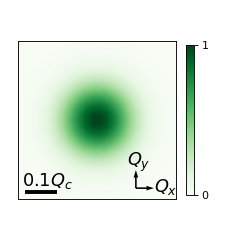

In [5]:
# betalpha = np.array([[0, 0], [np.pi, 0], [np.pi/2, 0], [np.pi/2, np.pi]])
sigma=1
l = 0
p=0
fig, ax = plt.subplots( figsize=(3, 3), constrained_layout=False, dpi=80)

qx = np.linspace(-0.25*Q_c, 0.25*Q_c, 50)
qy = np.linspace(-0.25*Q_c, 0.25*Q_c, 50)
QX, QY = np.meshgrid(qx, qy)
phiQ = np.arctan2(QY, QX)
Q = np.sqrt(QX**2+QY**2)

ax.cla()
ax.set_box_aspect(1)
ax.set_aspect('equal', adjustable='box')
ax.hlines(min(qy)+0.2, min(qx)+0.2, min(qx)+0.2+0.1*Q_c, color="k", linewidth=3.5, zorder=2)
ax.set_xlim(min(qx),max(qx))
ax.set_ylim(min(qy),max(qy))
ax.set_xticks([])
ax.set_yticks([])

globals()['CS'+str(0)]=ax.contourf(QX, QY, np.abs(F(l,Q)*np.exp(complex(0,1)*l*phiQ))**2/np.max(np.abs(F(l,Q)*np.exp(complex(0,1)*l*phiQ))**2),vmin=0, vmax=1,levels=800, cmap='Greens')

ax.quiver(max(qx)-1.1, min(qy)+0.3, 0, 0.8, scale=7, width=0.01, color='k', zorder=2)
ax.quiver(max(qx)-1.1, min(qy)+0.3, 0.8, 0, scale=7, width=0.01, color='k', zorder=2)
ax.text(max(qx)-1.35,  min(qy)+0.9,  '$Q_y$', fontsize=16, color='k')
ax.text(max(qx)-0.6,   min(qy)+0.2,  '$Q_x$', fontsize=16, color='k')
ax.text(min(qx)+0.1,   min(qy)+0.35, '$0.1 Q_c$', fontsize=16, color='k')
                                      
fig.colorbar(globals()['CS'+str(0)], shrink=0.78, format="{x:.0f}", ticks=np.linspace(0, 1, 2))

fig.subplots_adjust(left=0.075, bottom=0.1, right=0.9, top=0.9, wspace=0, hspace=0.06 )
# plt.tight_layout()
plt.show()

# 光學矩陣元 optical matrix element

C:\Users\nycugpu\AppData\Local\Temp\ipykernel_80536\2273367249.py:59: RuntimeWarning: invalid value encountered in divide
  globals()['CS'+str(1)]=ax[1].contourf(QX, QY, np.abs(matrixelement(ex, sigma, l, Q, phiQ))**2/np.max(np.abs(matrixelement(ex, sigma, l, Q, phiQ))**2),


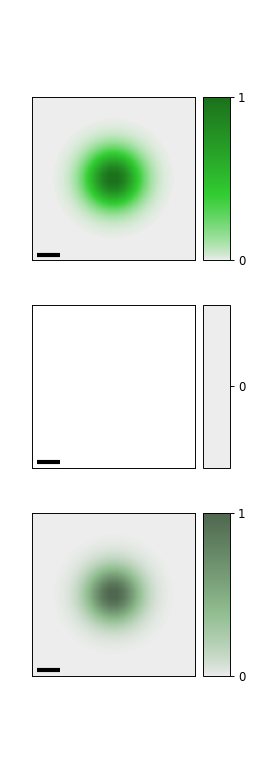

In [15]:
# betalpha = np.array([[0, 0], [np.pi, 0], [np.pi/2, 0], [np.pi/2, np.pi]])
sigma = -1
l = 0
p = 0
fig, ax = plt.subplots(3, 1, figsize=(3*1, 3*3), constrained_layout=False, dpi=85)

qx = np.linspace(-Q_c/np.sqrt(2), Q_c/np.sqrt(2), 50)
qy = np.linspace(-Q_c/np.sqrt(2), Q_c/np.sqrt(2), 50)
QX, QY = np.meshgrid(qx, qy)
phiQ = np.arctan2(QY, QX)
Q = np.sqrt(QX**2+QY**2)

def get_single_color_map(base_color, num_steps=256):
    # 1. 將輸入的顏色字串轉換為 RGB
    rgb = mcolors.to_rgb(base_color)
    
    # 2. 定義你想要的【統一極淺灰色】
    # (0.93, 0.93, 0.93) 是一種非常優雅、通透的淡灰色（接近網頁設計的 #edd 或 #f0f0f0）
    start_color = np.array([0.93, 0.93, 0.93])
    
    # 3. 建立 0.0 到 1.0 的非線性感知曲線（伽馬校正）
    x = np.linspace(0, 1, num_steps)
    non_linear_profile = np.power(x, 0.75) 
    
    rgb_list = []
    for val in non_linear_profile:
        if val < 0.5:
            # 前半段：從【固定淺灰】優雅、流暢地過渡到你的 base_color
            weight = val * 2
            r = start_color[0] + (rgb[0] - start_color[0]) * weight
            g = start_color[1] + (rgb[1] - start_color[1]) * weight
            b = start_color[2] + (rgb[2] - start_color[2]) * weight
        else:
            # 後半段：從你的 base_color 穩步加深，最大值降低明度以提高對比度
            weight = (val - 0.5) * 2
            r = rgb[0] * (1.0 - 0.45 * weight)
            g = rgb[1] * (1.0 - 0.45 * weight)
            b = rgb[2] * (1.0 - 0.45 * weight)
            
        rgb_list.append((r, g, b))
        
    return LinearSegmentedColormap.from_list("unified_gray_start_gradient", rgb_list, N=num_steps)

# FIXED: Loop index variable is safe as 'idx' so string reassignment does not break loop logic
for idx in range(3):
    ax[idx].cla()
    ax[idx].set_box_aspect(1)
    ax[idx].set_aspect('equal', adjustable='box')
    ax[idx].set_xlim(-0.5*Q_c/np.sqrt(2), 0.5*Q_c/np.sqrt(2))
    ax[idx].set_ylim(-0.5*Q_c/np.sqrt(2), 0.5*Q_c/np.sqrt(2))
    ax[idx].set_xticks([])
    ax[idx].set_yticks([])

    if idx==0:
        globals()['CS'+str(0)]=ax[0].contourf(QX, QY, np.abs(F(l,Q)*np.exp(complex(0,1)*l*phiQ))**2/np.max(np.abs(F(l,Q)*np.exp(complex(0,1)*l*phiQ))**2), 
                              vmin=0, vmax=1,levels=800, cmap=get_single_color_map('limegreen'))  
    if idx==1:
        ex = "circular_with_K"
        globals()['CS'+str(1)]=ax[1].contourf(QX, QY, np.abs(matrixelement(ex, sigma, l, Q, phiQ))**2/np.max(np.abs(matrixelement(ex, sigma, l, Q, phiQ))**2), 
                              vmin=0, vmax=1,levels=800, cmap=get_single_color_map('rosybrown'))
    elif idx==2:
        ex = "circular_with_Kprime"
        globals()['CS'+str(2)]=ax[2].contourf(QX, QY, np.abs(matrixelement(ex, sigma, l, Q, phiQ))**2/np.max(np.abs(matrixelement(ex, sigma, l, Q, phiQ))**2), 
                              vmin=0, vmax=1,levels=800, cmap=get_single_color_map('darkseagreen'))
    
#     if idx==1:
#         ex = "x_with_K"
#         globals()['CS'+str(1)]=ax[1].contourf(QX, QY, np.abs(matrixelement(ex, sigma, l, Q, phiQ))**2/np.max(np.abs(matrixelement(ex, sigma, l, Q, phiQ))**2), 
#                                    vmin=0, vmax=1,levels=800, cmap=get_single_color_map('rosybrown'))
#     elif idx==2:
#         ex = "x_with_Kprime"
#         globals()['CS'+str(2)]=ax[2].contourf(QX, QY, np.abs(matrixelement(ex, sigma, l, Q, phiQ))**2/np.max(np.abs(matrixelement(ex, sigma, l, Q, phiQ))**2), 
#                                    vmin=0, vmax=1,levels=800, cmap=get_single_color_map('darkseagreen'))
        
    # if idx==1:
    #     ex = "y_with_K"
    #     globals()['CS'+str(1)]=ax[1].contourf(QX, QY, np.abs(matrixelement(ex, sigma, l, Q, phiQ))**2/np.max(np.abs(matrixelement(ex, sigma, l, Q, phiQ))**2), 
    #                             vmin=0, vmax=1,levels=800, cmap=get_single_color_map('rosybrown'))
    # elif idx==2:
    #     ex = "y_with_Kprime"
    #     globals()['CS'+str(2)]=ax[2].contourf(QX, QY, np.abs(matrixelement(ex, sigma, l, Q, phiQ))**2/np.max(np.abs(matrixelement(ex, sigma, l, Q, phiQ))**2), 
    #                             vmin=0, vmax=1,levels=800, cmap=get_single_color_map('darkseagreen'))
    
    
    
    
    # if idx==1:
    #     ex = "circular_with_BP"
    #     globals()['CS'+str(1)]=ax[1].contourf(QX, QY, np.abs(matrixelement(ex, sigma, l, Q, phiQ))**2/np.max(np.abs(matrixelement(ex, sigma, l, Q, phiQ))**2), 
    #                           vmin=0, vmax=1,levels=800, cmap=get_single_color_map('rosybrown'))
    # elif idx==2:
    #     ex = "circular_with_BM"
    #     globals()['CS'+str(2)]=ax[2].contourf(QX, QY, np.abs(matrixelement(ex, sigma, l, Q, phiQ))**2/np.max(np.abs(matrixelement(ex, sigma, l, Q, phiQ))**2), 
    #                           vmin=0, vmax=1,levels=800, cmap=get_single_color_map('darkseagreen'))
    
#     if idx==1:
#         ex = "x_with_BP"
#         globals()['CS'+str(1)]=ax[1].contourf(QX, QY, np.abs(matrixelement(ex, sigma, l, Q, phiQ))**2/np.max(np.abs(matrixelement(ex, sigma, l, Q, phiQ))**2), 
#                                    vmin=0, vmax=1,levels=800, cmap=get_single_color_map('rosybrown'))
#     elif idx==2:
#         ex = "x_with_BM"
#         globals()['CS'+str(2)]=ax[2].contourf(QX, QY, np.abs(matrixelement(ex, sigma, l, Q, phiQ))**2/np.max(np.abs(matrixelement(ex, sigma, l, Q, phiQ))**2), 
#                                    vmin=0, vmax=1,levels=800, cmap=get_single_color_map('darkseagreen'))

#     if idx==1:
#         ex = "y_with_BP"
#         globals()['CS'+str(1)]=ax[1].contourf(QX, QY, np.abs(matrixelement(ex, sigma, l, Q, phiQ))**2/np.max(np.abs(matrixelement(ex, sigma, l, Q, phiQ))**2), 
#                                 vmin=0, vmax=1,levels=800, cmap=get_single_color_map('rosybrown'))
#     elif idx==2:
#         ex = "y_with_BM"
#         globals()['CS'+str(2)]=ax[2].contourf(QX, QY, np.abs(matrixelement(ex, sigma, l, Q, phiQ))**2/np.max(np.abs(matrixelement(ex, sigma, l, Q, phiQ))**2), 
#                                 vmin=0, vmax=1,levels=800, cmap=get_single_color_map('darkseagreen'))
        
    ax[idx].hlines(-0.5*Q_c/np.sqrt(2)+0.2, -0.5*Q_c/np.sqrt(2)+0.2, -0.5*Q_c/np.sqrt(2)+0.2+0.1*Q_c, color="k", linewidth=3.5, zorder=5)
        
#plum lightsteelblue rosybrown darkseagreen darksalmon darkkhaki
        
# for ex in range(3):
    # ax[ex].quiver(max(qx)-1.1, min(qy)+0.3, 0, 0.8, scale=7, width=0.01, color='k', zorder=2)
    # ax[ex].quiver(max(qx)-1.1, min(qy)+0.3, 0.8, 0, scale=7, width=0.01, color='k', zorder=2)
    # ax[ex].text(max(qx)-1.35,  min(qy)+0.9,  '$Q_y$', fontsize=16, color='k')
    # ax[ex].text(max(qx)-0.6,   min(qy)+0.2,  '$Q_x$', fontsize=16, color='k')
    # ax[ex].text(min(qx)+0.1,   min(qy)+0.35, '$0.1 Q_c$', fontsize=16, color='k')


# =====================================================================
# --- DEDICATED THICKNESS CONTROL SECTION (axes_grid1 Approach) ---
# =====================================================================
from mpl_toolkits.axes_grid1 import make_axes_locatable

# Change this percentage to make the colorbars dedicatedly wider or narrower!
# Try "6%", "8%", "10%", etc. It won't shrink your square plots anymore.
cbar_thickness = "16%"  

for idx in range(3):
    divider = make_axes_locatable(ax[idx])
    # Append an explicit axis container on the right side of your plot
    cax = divider.append_axes("right", size=cbar_thickness, pad=0.1)
    
    fig.colorbar(globals()['CS'+str(idx)], cax=cax, format="{x:.0f}", ticks=np.linspace(0, 1, 2))


# Because axes_grid1 locks layout spaces, we widen the right margin layout edge 
# from 0.90 to 0.85 to make sure the colorbars fit beautifully

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.colors import LinearSegmentedColormap
from mpl_toolkits.axes_grid1 import make_axes_locatable
import ipywidgets as widgets
from IPython.display import display, clear_output

# ---------------------------------------------------------------------
# 1. 基礎設定與矩陣定義
# ---------------------------------------------------------------------
POLARIZATIONS = {
    'x': np.array([1, 0]),
    'y': np.array([0, 1]),
    'pluscircular': np.array([1, 1j]) / np.sqrt(2),
    'minuscircular': np.array([1, -1j]) / np.sqrt(2)
}

def get_D_matrix(mode, phiQ):
    if mode == "K":
        return np.conj([1, 1j])
    elif mode == "Kprime":
        return np.conj([1, -1j])
    elif mode == "BP":
        return np.conj([np.cos(phiQ), np.sin(phiQ)])
    elif mode == "BM":
        return np.conj([-1j * np.sin(phiQ), 1j * np.cos(phiQ)])

def matrixelement(ex, sigma, l, Q, phiQ):  
    pol_type, mode = ex.split('_with_')
    
    if pol_type == 'circular':
        pol_vec = POLARIZATIONS['pluscircular'] if sigma == 1 else POLARIZATIONS['minuscircular']
    else:
        pol_vec = POLARIZATIONS[pol_type]
        
    D_vec = get_D_matrix(mode, phiQ)
    inner_prod = pol_vec[0] * D_vec[0] + pol_vec[1] * D_vec[1]
    
    return 1 / (2j) * F(l, Q) * np.exp(1j * l * phiQ) * inner_prod

def get_single_color_map(base_color, num_steps=256):
    rgb = mcolors.to_rgb(base_color)
    start_color = np.array([0.93, 0.93, 0.93])
    x = np.linspace(0, 1, num_steps)
    non_linear_profile = np.power(x, 0.75) 
    
    rgb_list = []
    for val in non_linear_profile:
        if val < 0.5:
            weight = val * 2
            r = start_color[0] + (rgb[0] - start_color[0]) * weight
            g = start_color[1] + (rgb[1] - start_color[1]) * weight
            b = start_color[2] + (rgb[2] - start_color[2]) * weight
        else:
            weight = (val - 0.5) * 2
            r = rgb[0] * (1.0 - 0.45 * weight)
            g = rgb[1] * (1.0 - 0.45 * weight)
            b = rgb[2] * (1.0 - 0.45 * weight)
        rgb_list.append((r, g, b))
        
    return LinearSegmentedColormap.from_list("unified_gray_start_gradient", rgb_list, N=num_steps)

# ---------------------------------------------------------------------
# 2. 定義 6 種組合與對應名稱
# ---------------------------------------------------------------------
EX_OPTIONS = {
    'Circular + K/K′': ('circular_with_K', 'circular_with_Kprime'),
    'X-pol + K/K′':    ('x_with_K',        'x_with_Kprime'),
    'Y-pol + K/K′':    ('y_with_K',        'y_with_Kprime'),
    'Circular + BP/BM':('circular_with_BP', 'circular_with_BM'),
    'X-pol + BP/BM':   ('x_with_BP',       'x_with_BM'),
    'Y-pol + BP/BM':   ('y_with_BP',       'y_with_BM'),
}

# ---------------------------------------------------------------------
# 3. 繪圖核心函數 (接收 selected_label, sigma_val, l_val)
# ---------------------------------------------------------------------
def plot_selected_mode(selected_label, sigma_val, l_val):
    sigma = sigma_val
    l = l_val  # 動態帶入使用者選擇的 l

    qx = np.linspace(-Q_c/np.sqrt(2), Q_c/np.sqrt(2), 150)
    qy = np.linspace(-Q_c/np.sqrt(2), Q_c/np.sqrt(2), 150)
    QX, QY = np.meshgrid(qx, qy)
    phiQ = np.arctan2(QY, QX)
    Q = np.sqrt(QX**2 + QY**2)

    ex1, ex2 = EX_OPTIONS[selected_label]

    # BP/BM 組合配色切換為 plum / lightsteelblue
    if "BP/BM" in selected_label:
        color1 = 'plum'
        color2 = 'lightsteelblue'
    else:
        color1 = 'rosybrown'
        color2 = 'darkseagreen'

    fig, ax = plt.subplots(3, 1, figsize=(3*1, 3*3), constrained_layout=False, dpi=105)
    CS = [None] * 3

    for idx in range(3):
        ax[idx].cla()
        ax[idx].set_box_aspect(1)
        ax[idx].set_aspect('equal', adjustable='box')
        ax[idx].set_xlim(-0.5*Q_c/np.sqrt(2), 0.5*Q_c/np.sqrt(2))
        ax[idx].set_ylim(-0.5*Q_c/np.sqrt(2), 0.5*Q_c/np.sqrt(2))
        ax[idx].set_xticks([])
        ax[idx].set_yticks([])

        if idx == 0:
            Z = np.abs(F(l, Q) * np.exp(1j * l * phiQ))**2
            cmap_color = 'limegreen'
        elif idx == 1:
            Z = np.abs(matrixelement(ex1, sigma, l, Q, phiQ))**2
            cmap_color = color1
        elif idx == 2:
            Z = np.abs(matrixelement(ex2, sigma, l, Q, phiQ))**2
            cmap_color = color2

        # 安全歸一化：避免 max(Z) = 0 時除以零
        z_max = np.max(Z)
        Z_norm = Z / z_max if z_max > 1e-15 else Z

        CS[idx] = ax[idx].contourf(
            QX, QY, Z_norm, 
            vmin=0, vmax=1, levels=800, 
            cmap=get_single_color_map(cmap_color)
        )

        ax[idx].hlines(-0.5*Q_c/np.sqrt(2)+0.2, -0.5*Q_c/np.sqrt(2)+0.2, -0.5*Q_c/np.sqrt(2)+0.2+0.1*Q_c, color="k", linewidth=3.5, zorder=5)

    cbar_thickness = "16%"
    for idx in range(3):
        divider = make_axes_locatable(ax[idx])
        cax = divider.append_axes("right", size=cbar_thickness, pad=0.1)
        fig.colorbar(CS[idx], cax=cax, format="{x:.0f}", ticks=np.linspace(0, 1, 2))

    plt.show()

# ---------------------------------------------------------------------
# 4. ipywidgets 控制介面 (Dropdown + IntText)
# ---------------------------------------------------------------------
# 1. 6 選 1 按鈕
mode_selector = widgets.ToggleButtons(
    options=list(EX_OPTIONS.keys()),
    description='組合選擇:',
    disabled=False,
    button_style='info', 
    tooltips=['選擇欲繪制的極化與能谷/帶組合'],
)

# 2. σ 下拉選單 (Dropdown)
sigma_selector = widgets.Dropdown(
    options=[('σ = +1', 1), ('σ = -1', -1)],
    value=-1,
    description='偏振 (σ):',
    layout=widgets.Layout(width='180px')
)

# 3. l 整數輸入框 (IntText)
l_selector = widgets.IntText(
    value=0,
    step=1,
    description='角動量 (l):',
    layout=widgets.Layout(width='180px')
)

# 4. Plot 圖表觸發按鈕
plot_button = widgets.Button(
    description='Plot Figure',
    button_style='success',
    icon='paint-brush'
)

output_area = widgets.Output()

def on_plot_button_clicked(b):
    with output_area:
        clear_output(wait=True)
        # 傳入 組合、sigma、l 三項參數
        plot_selected_mode(mode_selector.value, sigma_selector.value, l_selector.value)

plot_button.on_click(on_plot_button_clicked)

# 排版：將 Dropdown 與 IntText 水平並排
param_box = widgets.HBox([sigma_selector, l_selector])

display(widgets.VBox([
    mode_selector,
    param_box,
    plot_button,
    output_area
]))

# Exciton wavepacket

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, LightSource
import ipywidgets as widgets
from IPython.display import display, clear_output

# ---------------------------------------------------------------------
# 0. 固定基準值設定 (l=0, x-pol, K valley 下的最大強度)
# ---------------------------------------------------------------------
REF_MAX = 1.0844188961e+02

# ---------------------------------------------------------------------
# 1. 基礎設定與矩陣定義
# ---------------------------------------------------------------------
POLARIZATIONS = {
    'x': np.array([1, 0]),
    'y': np.array([0, 1]),
    'pluscircular': np.array([1, 1j]) / np.sqrt(2),
    'minuscircular': np.array([1, -1j]) / np.sqrt(2)
}

def get_D_matrix(mode, phiQ):
    if mode == "K":
        return np.conj([1, 1j])
    elif mode == "Kprime":
        return np.conj([1, -1j])
    elif mode == "BP":
        return np.conj([np.cos(phiQ), np.sin(phiQ)])
    elif mode == "BM":
        return np.conj([-1j * np.sin(phiQ), 1j * np.cos(phiQ)])

def matrixelement(ex, sigma, l, Q, phiQ):  
    pol_type, mode = ex.split('_with_')
    
    if pol_type == 'circular':
        pol_vec = POLARIZATIONS['pluscircular'] if sigma == 1 else POLARIZATIONS['minuscircular']
    else:
        pol_vec = POLARIZATIONS[pol_type]
        
    D_vec = get_D_matrix(mode, phiQ)
    inner_prod = pol_vec[0] * D_vec[0] + pol_vec[1] * D_vec[1]
    
    # return 1 / (2j) * F(l, Q) * np.exp(1j * l * phiQ) * inner_prod
    return 1 / (2j) * F(l, Q) * np.exp(1j * l * phiQ) * inner_prod * np.exp(1j * 1 * phiQ) 

# ---------------------------------------------------------------------
# 2. 向量化 2D 矩陣積分 (極速計算 3D 波包)
# ---------------------------------------------------------------------
def fs2_vectorized(ex, sigma, l, R, phiR, num_Q=50, num_phiQ=50):
    Q_arr = np.linspace(0, 4, num_Q)
    phiQ_arr = np.linspace(0, 2 * np.pi, num_phiQ)
    
    Q_grid = Q_arr[:, None, None, None]
    phiQ_grid = phiQ_arr[None, :, None, None]
    R_grid = R[None, None, :, :]
    phiR_grid = phiR[None, None, :, :]
    
    mat_elem = matrixelement(ex, sigma, l, Q_grid, phiQ_grid)
    phase = np.exp(1j * Q_grid * R_grid * np.cos(phiQ_grid - phiR_grid))
    integrand = mat_elem * phase * Q_grid
    
    integral_phiQ = np.trapz(integrand, phiQ_arr, axis=1)
    integral_total = np.trapz(integral_phiQ, Q_arr, axis=0)
    
    return integral_total

def get_single_color_map(base_color):
    return LinearSegmentedColormap.from_list("custom", [base_color, base_color, base_color])

# ---------------------------------------------------------------------
# 3. 6 種組合模式對照
# ---------------------------------------------------------------------
EX_OPTIONS = {
    'Circular + K/K′': ('circular_with_K', 'circular_with_Kprime'),
    'X-pol + K/K′':    ('x_with_K',        'x_with_Kprime'),
    'Y-pol + K/K′':    ('y_with_K',        'y_with_Kprime'),
    'Circular + BP/BM':('circular_with_BP', 'circular_with_BM'),
    'X-pol + BP/BM':   ('x_with_BP',       'x_with_BM'),
    'Y-pol + BP/BM':   ('y_with_BP',       'y_with_BM'),
}

# ---------------------------------------------------------------------
# 4. 3D 波包繪圖核心函數 (固定以 REF_MAX 為基準)
# ---------------------------------------------------------------------
def plot_3d_wavepacket(selected_label, sigma_val, l_val):
    sigma = sigma_val
    l = l_val

    x = np.linspace(-3*W, 3*W, 250)
    y = np.linspace(-3*W, 3*W, 250)
    X, Y = np.meshgrid(x, y)
    phiR = np.arctan2(Y, X)
    R = np.sqrt(X**2 + Y**2)

    ex1, ex2 = EX_OPTIONS[selected_label]

    if "BP/BM" in selected_label:
        color1, color2 = 'plum', 'lightsteelblue'
    else:
        color1, color2 = 'rosybrown', 'darkseagreen'

    fig, ax = plt.subplots(2, 1, figsize=(3, 5), 
                           subplot_kw={'projection': '3d'}, 
                           constrained_layout=False, dpi=150)

    data1 = np.abs(fs2_vectorized(ex1, sigma, l, R, phiR))**2
    data2 = np.abs(fs2_vectorized(ex2, sigma, l, R, phiR))**2

    current_max = max(np.max(data1), np.max(data2))
    rel_ratio = (current_max / REF_MAX) * 100
    print(f"Current Params: Mode={selected_label}, σ={sigma}, l={l}")
    print(f"Current Max = {current_max:.4e} | Relative to Ref (l=0, x-K) = {rel_ratio:.2f}%")

    modes = [(ex1, color1, data1), (ex2, color2, data2)]

    for ex in range(2):
        mode_name, color_base, data = modes[ex]

        ax[ex].cla()
        ax[ex].set_xlim(min(x), max(x))
        ax[ex].set_ylim(min(y), max(y))
        ax[ex].set_zlim(0, 1)
        ax[ex].set_axis_off()
        ax[ex].set_xticks([])
        ax[ex].set_yticks([])
        ax[ex].set_zticks([])
        ax[ex].set_xlabel('x (um)')
        ax[ex].set_ylabel('y (um)')
        
        # 仰角稍微提高一點點，更能突顯拉高的山峰
        ax[ex].view_init(elev=28, azim=-118)
        ax[ex].dist = 7.5

        # 【關鍵修改】高度比例從 0.35 放大至 0.7（可依喜好微調成 0.6 ~ 0.85）
        z_norm = 0.7 * (data / REF_MAX)

        ls = LightSource(azdeg=315, altdeg=65)
        cmap = get_single_color_map(color_base)
        
        # 增加光影垂直誇張度，讓地形更陡峭
        rgb = ls.shade(z_norm, cmap=cmap, vert_exag=80, blend_mode='soft')

        ax[ex].plot_surface(X, Y, z_norm, 
                            facecolors=rgb, 
                            linewidth=0, 
                            antialiased=False, 
                            shade=False, 
                            zorder=2)

    n = np.linspace(min(x), min(x) + W, 10)
    m = np.linspace(min(y), min(y) + 0.3 * W, 10)
    n, m = np.meshgrid(n, m)
    ax[0].plot_surface(n, m, n*0 + m*0 + 0.1, linewidth=0, color='k', zorder=0)
    ax[1].plot_surface(n, m, n*0 + m*0 + 0.1, linewidth=0, color='k', zorder=0)

    fig.subplots_adjust(left=0.0, right=1.0, top=0.98, bottom=0.02, hspace=-0.05)

    plt.show()

# ---------------------------------------------------------------------
# 5. ipywidgets 控制介面
# ---------------------------------------------------------------------
mode_selector = widgets.ToggleButtons(
    options=list(EX_OPTIONS.keys()),
    description='組合選擇:',
    disabled=False,
    button_style='info', 
    tooltips=['選擇欲繪制的極化與能谷/帶組合'],
)

sigma_selector = widgets.Dropdown(
    options=[('σ = +1', 1), ('σ = -1', -1)],
    value=-1,
    description='偏振 (σ):',
    layout=widgets.Layout(width='180px')
)

l_selector = widgets.IntText(
    value=0,
    step=1,
    description='角動量 (l):',
    layout=widgets.Layout(width='180px')
)

plot_button = widgets.Button(
    description='Plot Figure',
    button_style='success',
    icon='paint-brush'
)

output_area = widgets.Output()

def on_plot_button_clicked(b):
    with output_area:
        clear_output(wait=True)
        plot_3d_wavepacket(mode_selector.value, sigma_selector.value, l_selector.value)

plot_button.on_click(on_plot_button_clicked)

param_box = widgets.HBox([sigma_selector, l_selector])

display(widgets.VBox([
    mode_selector,
    param_box,
    plot_button,
    output_area
]))

In [5]:
import numpy as np

# 1. 建立對應的 2D 空間網格 (請確保與主程式的網格範圍 W 一致)
x_ref = np.linspace(-3*W, 3*W, 50)
y_ref = np.linspace(-3*W, 3*W, 50)
X_ref, Y_ref = np.meshgrid(x_ref, y_ref)
phiR_ref = np.arctan2(Y_ref, X_ref)
R_ref = np.sqrt(X_ref**2 + Y_ref**2)

# 2. 計算 l=0, x-polarization, K valley 下的波包強度 2D 陣列
ref_data = np.abs(fs2_vectorized(ex='x_with_K', sigma=1, l=0, R=R_ref, phiR=phiR_ref))**2

# 3. 取得最大峰值數字
REF_MAX_VALUE = np.max(ref_data)

print("=" * 50)
print(f"基準高度 (REF_MAX_VALUE) = {REF_MAX_VALUE:.10e}")
print("=" * 50)

基準高度 (REF_MAX_VALUE) = 2.1911471092e+01


# 輸出DATA

In [5]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, LightSource
import ipywidgets as widgets
from IPython.display import display, clear_output
import pandas as pd

# ---------------------------------------------------------------------
# 0. 固定基準值設定 (l=0, x-pol, K valley 下的最大強度)
# ---------------------------------------------------------------------
REF_MAX = 1.0844188961e+02
W = 1.5  # 確保 W 有定義，避免繪圖計算未定義

# ---------------------------------------------------------------------
# 1. 基礎設定與矩陣定義
# ---------------------------------------------------------------------
POLARIZATIONS = {
    'x': np.array([1, 0]),
    'y': np.array([0, 1]),
    'pluscircular': np.array([1, 1j]) / np.sqrt(2),
    'minuscircular': np.array([1, -1j]) / np.sqrt(2)
}

def get_D_matrix(mode, phiQ):
    if mode == "K":
        return np.conj([1, 1j])
    elif mode == "Kprime":
        return np.conj([1, -1j])
    elif mode == "BP":
        return np.conj([np.cos(phiQ), np.sin(phiQ)])
    elif mode == "BM":
        return np.conj([-1j * np.sin(phiQ), 1j * np.cos(phiQ)])

def matrixelement(ex, sigma, l, Q, phiQ):  
    pol_type, mode = ex.split('_with_')
    
    if pol_type == 'circular':
        pol_vec = POLARIZATIONS['pluscircular'] if sigma == 1 else POLARIZATIONS['minuscircular']
    else:
        pol_vec = POLARIZATIONS[pol_type]
        
    D_vec = get_D_matrix(mode, phiQ)
    inner_prod = pol_vec[0] * D_vec[0] + pol_vec[1] * D_vec[1]
    
    return 1 / (2j) * F(l, Q) * np.exp(1j * l * phiQ) * inner_prod  
    # return 1 / (2j) * F(l, Q) * np.exp(1j * l * phiQ) * inner_prod * np.exp(1j * 1 * phiQ) 

# ---------------------------------------------------------------------
# 2. 向量化 2D 矩陣積分 (極速計算 3D 波包)
# ---------------------------------------------------------------------
def fs2_vectorized(ex, sigma, l, R, phiR, num_Q=100, num_phiQ=60, chunk_size=100):
    Q_arr = np.linspace(0, 15, num_Q)
    phiQ_arr = np.linspace(0, 2 * np.pi, num_phiQ)
    
    Q_grid = Q_arr[:, None, None, None]
    phiQ_grid = phiQ_arr[None, :, None, None]
    
    # 預先算出與實空間無關的矩陣元素 (減少重複計算)
    mat_elem = matrixelement(ex, sigma, l, Q_grid, phiQ_grid)
    
    Ny, Nx = R.shape
    integral_total = np.zeros((Ny, Nx), dtype=complex)
    
    # 將 y 軸分塊 (Chunking) 處理，避免 4D 陣列膨脹爆記憶體
    for i in range(0, Ny, chunk_size):
        R_chunk = R[i:i+chunk_size, :][None, None, :, :]
        phiR_chunk = phiR[i:i+chunk_size, :][None, None, :, :]
        
        phase = np.exp(1j * Q_grid * R_chunk * np.cos(phiQ_grid - phiR_chunk))
        integrand = mat_elem * phase * Q_grid
        
        integral_phiQ = np.trapz(integrand, phiQ_arr, axis=1)
        integral_total[i:i+chunk_size, :] = np.trapz(integral_phiQ, Q_arr, axis=0)
        
    return integral_total

def get_single_color_map(base_color):
    return LinearSegmentedColormap.from_list("custom", [base_color, base_color, base_color])

# ---------------------------------------------------------------------
# 3. 6 種組合模式對照
# ---------------------------------------------------------------------
EX_OPTIONS = {
    'Circular + K/K′': ('circular_with_K', 'circular_with_Kprime'),
    'X-pol + K/K′':    ('x_with_K',        'x_with_Kprime'),
    'Y-pol + K/K′':    ('y_with_K',        'y_with_Kprime'),
    'Circular + BP/BM':('circular_with_BP', 'circular_with_BM'),
    'X-pol + BP/BM':   ('x_with_BP',       'x_with_BM'),
    'Y-pol + BP/BM':   ('y_with_BP',       'y_with_BM'),
}

# ---------------------------------------------------------------------
# 4. 數據計算與 CSV 匯出邏輯 (一次匯出 4 種偏振資料)
# ---------------------------------------------------------------------
def export_all_pols_csv(target_group, l_val):
    l = l_val

    x = np.linspace(-8*W, 8*W, 1000)
    y = np.linspace(-8*W, 8*W, 1000)
    X, Y = np.meshgrid(x, y)
    phiR = np.arctan2(Y, X)
    R = np.sqrt(X**2 + Y**2)

    # 4 種偏振組態設定
    pols_config = [
        ('circular', 1,  'sig_plus'),
        ('circular', -1, 'sig_minus'),
        ('x',        0,  'xpol'),
        ('y',        0,  'ypol')
    ]

    data_dict = {
        'x': X.ravel(),
        'y': Y.ravel()
    }

    if target_group == 'KK':
        prefix = "KK"
        mode1_name, mode2_name = "K", "Kprime"
    else: # 'BX'
        prefix = "BX"
        mode1_name, mode2_name = "BP", "BM"

    filename = f"{prefix}_l_{l}.csv"

    # 依序計算 4 種偏振 (共 8 個 Mode 數據欄位)
    for pol_type, sigma, pol_tag in pols_config:
        ex1 = f"{pol_type}_with_{mode1_name}"
        ex2 = f"{pol_type}_with_{mode2_name}"

        data1 = np.abs(fs2_vectorized(ex1, sigma, l, R, phiR))**2
        data2 = np.abs(fs2_vectorized(ex2, sigma, l, R, phiR))**2

        if target_group == 'KK':
            col1 = f"K_valley_{pol_tag}"
            col2 = f"Kprime_valley_{pol_tag}"
        else:
            col1 = f"upperBX_{pol_tag}"
            col2 = f"lowerBX_{pol_tag}"

        data_dict[col1] = data1.ravel()
        data_dict[col2] = data2.ravel()

    df = pd.DataFrame(data_dict)

    # 簡化後的標頭註解：已移除 REF_MAX 與 Polarizations 資訊
    header_comment = (
        f"# Group: {target_group} ({mode1_name} vs {mode2_name})\n"
        f"# Parameters: l = {l}\n"
    )

    with open(filename, 'w', encoding='utf-8-sig', newline='') as f:
        f.write(header_comment)
        df.to_csv(f, index=False, lineterminator='\n')

    print(f"✅ 成功匯出 4 種偏振數據至：{os.path.abspath(filename)}")

# ---------------------------------------------------------------------
# 5. 3D 波包繪圖核心函數
# ---------------------------------------------------------------------
def plot_3d_wavepacket(selected_label, sigma_val, l_val):
    sigma = sigma_val
    l = l_val

    x = np.linspace(-3*W, 3*W, 180)
    y = np.linspace(-3*W, 3*W, 180)
    X, Y = np.meshgrid(x, y)
    phiR = np.arctan2(Y, X)
    R = np.sqrt(X**2 + Y**2)

    ex1, ex2 = EX_OPTIONS[selected_label]

    if "BP/BM" in selected_label:
        color1, color2 = 'plum', 'lightsteelblue'
    else:
        color1, color2 = 'rosybrown', 'darkseagreen'

    fig, ax = plt.subplots(2, 1, figsize=(3, 5), 
                           subplot_kw={'projection': '3d'}, 
                           constrained_layout=False, dpi=150)

    data1 = np.abs(fs2_vectorized(ex1, sigma, l, R, phiR))**2
    data2 = np.abs(fs2_vectorized(ex2, sigma, l, R, phiR))**2

    current_max = max(np.max(data1), np.max(data2))
    rel_ratio = (current_max / REF_MAX) * 100
    print(f"Current Params: Mode={selected_label}, σ={sigma}, l={l}")
    print(f"Current Max = {current_max:.4e} | Relative to Ref (l=0, x-K) = {rel_ratio:.2f}%")

    modes = [(ex1, color1, data1), (ex2, color2, data2)]

    for ex in range(2):
        mode_name, color_base, data = modes[ex]

        ax[ex].cla()
        ax[ex].set_xlim(min(x), max(x))
        ax[ex].set_ylim(min(y), max(y))
        ax[ex].set_zlim(0, 1)
        ax[ex].set_axis_off()
        ax[ex].set_xticks([])
        ax[ex].set_yticks([])
        ax[ex].set_zticks([])
        ax[ex].set_xlabel('x (um)')
        ax[ex].set_ylabel('y (um)')
        
        ax[ex].view_init(elev=28, azim=-118)
        ax[ex].dist = 7.5

        z_norm = 0.7 * (data / REF_MAX)

        ls = LightSource(azdeg=315, altdeg=65)
        cmap = get_single_color_map(color_base)
        
        rgb = ls.shade(z_norm, cmap=cmap, vert_exag=80, blend_mode='soft')

        ax[ex].plot_surface(X, Y, z_norm, 
                            facecolors=rgb, 
                            linewidth=0, 
                            antialiased=False, 
                            shade=False, 
                            zorder=2)

    n = np.linspace(min(x), min(x) + W, 10)
    m = np.linspace(min(y), min(y) + 0.3 * W, 10)
    n, m = np.meshgrid(n, m)
    ax[0].plot_surface(n, m, n*0 + m*0 + 0.1, linewidth=0, color='k', zorder=0)
    ax[1].plot_surface(n, m, n*0 + m*0 + 0.1, linewidth=0, color='k', zorder=0)

    fig.subplots_adjust(left=0.0, right=1.0, top=0.98, bottom=0.02, hspace=-0.05)

    plt.show()

# ---------------------------------------------------------------------
# 6. ipywidgets 控制介面 (分開 KK 與 BP/BM 兩組獨立 Export 按鈕)
# ---------------------------------------------------------------------
mode_selector = widgets.ToggleButtons(
    options=list(EX_OPTIONS.keys()),
    description='組合選擇:',
    disabled=False,
    button_style='info', 
    tooltips=['選擇欲繪制的極化與能谷/帶組合'],
)

sigma_selector = widgets.Dropdown(
    options=[('σ = +1', 1), ('σ = -1', -1)],
    value=-1,
    description='偏振 (σ):',
    layout=widgets.Layout(width='180px')
)

l_selector = widgets.IntText(
    value=0,
    step=1,
    description='角動量 (l):',
    layout=widgets.Layout(width='180px')
)

plot_button = widgets.Button(
    description='Plot Figure',
    button_style='success',
    icon='paint-brush'
)

export_kk_button = widgets.Button(
    description='Export KK CSV',
    button_style='warning',
    icon='download'
)

export_bx_button = widgets.Button(
    description='Export BP/BM CSV',
    button_style='danger',
    icon='download'
)

output_area = widgets.Output()

def on_plot_button_clicked(b):
    with output_area:
        clear_output(wait=True)
        plot_3d_wavepacket(mode_selector.value, sigma_selector.value, l_selector.value)

def on_export_kk_clicked(b):
    with output_area:
        print(f"⏳ 正在計算並匯出 KK (4種偏振) 數據至 CSV 中 (l={l_selector.value})...")
        export_all_pols_csv('KK', l_selector.value)

def on_export_bx_clicked(b):
    with output_area:
        print(f"⏳ 正在計算並匯出 BP/BM (4種偏振) 數據至 CSV 中 (l={l_selector.value})...")
        export_all_pols_csv('BX', l_selector.value)

plot_button.on_click(on_plot_button_clicked)
export_kk_button.on_click(on_export_kk_clicked)
export_bx_button.on_click(on_export_bx_clicked)

param_box = widgets.HBox([sigma_selector, l_selector])
button_box = widgets.HBox([plot_button, export_kk_button, export_bx_button])

display(widgets.VBox([
    mode_selector,
    param_box,
    button_box,
    output_area
]))

# 以輸出的csv檔案重新繪製wave packet對照

🔍 開始檢查檔案與 Excel 相容性...
  - 總行數: 490003 行
  - 中元資料 (列 1): # Group: KK (K vs Kprime)
  - 中元資料 (列 2): # Parameters: l = 1
  - Data 欄位標題: x,y,K_valley_sig_plus,Kprime_valley_sig_plus,K_valley_sig_minus,Kprime_valley_sig_minus,K_valley_xpol,Kprime_valley_xpol,K_valley_ypol,Kprime_valley_ypol
  - ✅ 空白行檢查：完美！無多餘空白行。

🐍 開始進行 Python 數據讀取與維度重建...
  - 上排欄位 (Mode 1): ['K_valley_sig_plus', 'K_valley_sig_minus', 'K_valley_xpol', 'K_valley_ypol']
  - 下排欄位 (Mode 2): ['Kprime_valley_sig_plus', 'Kprime_valley_sig_minus', 'Kprime_valley_xpol', 'Kprime_valley_ypol']


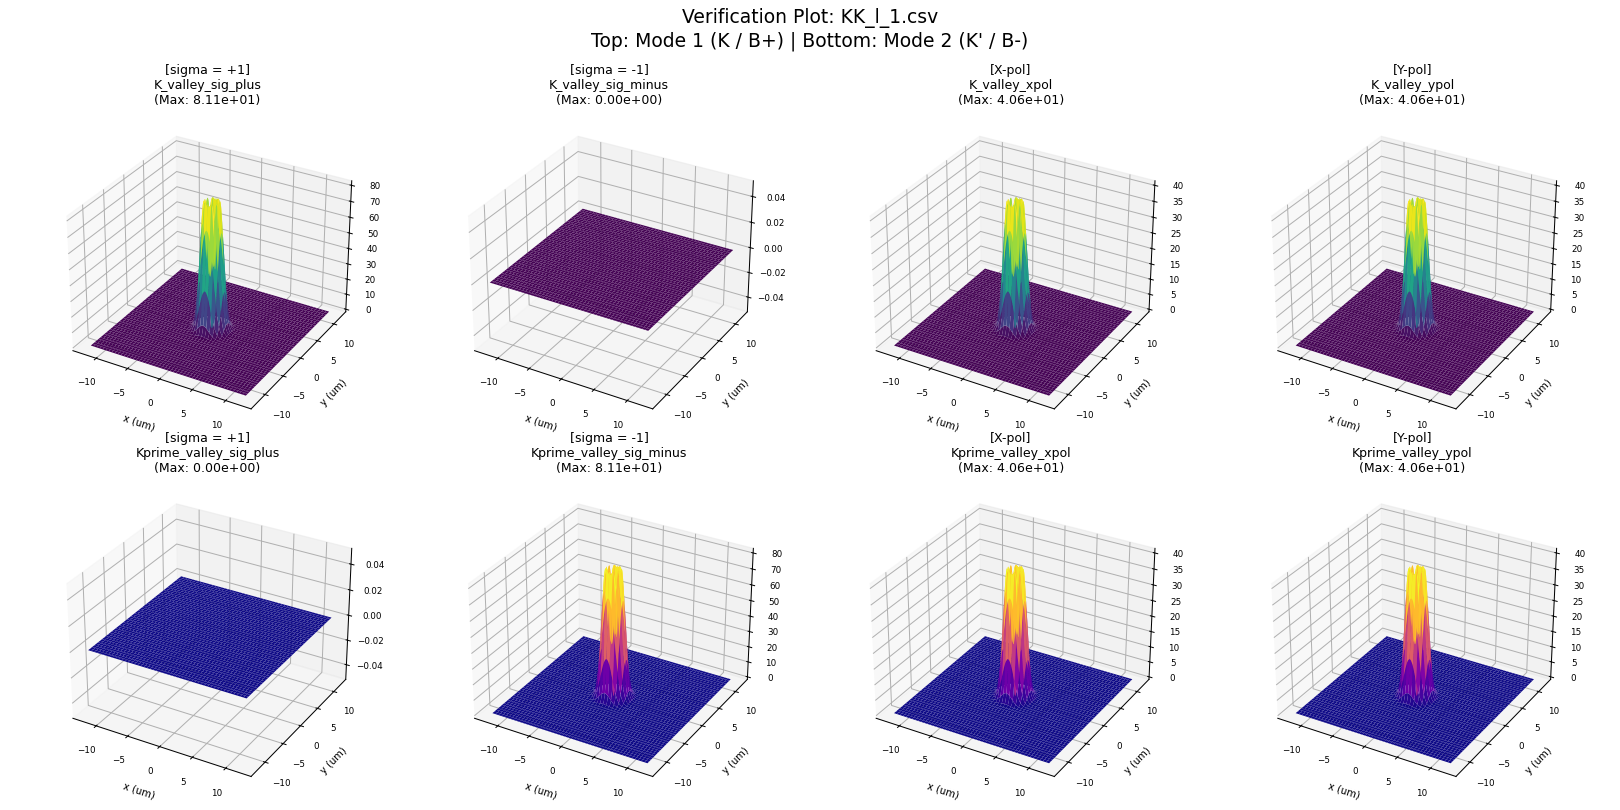

🎉 驗證完成！使用預設全範圍繪圖。


In [8]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# filename = "KK_l_0.csv"
# filename = "KK_l_-1.csv"
filename = "KK_l_1.csv"
# filename = "BX_l_0.csv"
# filename = "BX_l_1.csv"
# filename = "BXprime_l_0.csv"
# filename = "BXprime_l_1.csv"

# ---------------------------------------------------------------------
# 範圍控制設定 (註解掉或設為 None 即可恢復全範圍繪圖)
# ---------------------------------------------------------------------
# LIMIT_XY = 4.5  # 限制 x, y 軸於 +-4.5 微米；要恢復原本範圍請註解此行：# LIMIT_XY = 4.5

# ===============================================================
# 1. EXCEL 相容性與結構檢查
# ===============================================================
print("🔍 開始檢查檔案與 Excel 相容性...")

if not os.path.exists(filename):
    print(f"❌ 找不到檔案 {filename}，請先執行匯出按鈕！")
else:
    with open(filename, 'r', encoding='utf-8-sig') as f:
        lines = f.readlines()
    
    empty_lines = [i for i, line in enumerate(lines) if line.strip() == '']
    
    print(f"  - 總行數: {len(lines)} 行")
    print(f"  - 中元資料 (列 1): {lines[0].strip()}")
    print(f"  - 中元資料 (列 2): {lines[1].strip()}")
    print(f"  - Data 欄位標題: {lines[2].strip()}")
    
    if len(empty_lines) == 0:
        print("  - ✅ 空白行檢查：完美！無多餘空白行。")
    else:
        print(f"  - ⚠️ 警告：偵測到 {len(empty_lines)} 行空白列！")

# ===============================================================
# 2. PYTHON 讀取與數據分類
# ===============================================================
print("\n🐍 開始進行 Python 數據讀取與維度重建...")

df = pd.read_csv(filename, comment='#')
N = int(np.sqrt(len(df)))

X = df['x'].values.reshape(N, N)
Y = df['y'].values.reshape(N, N)

# 取得所有數據欄位 (共 8 個)
data_cols = [c for c in df.columns if c not in ['x', 'y']]

# 定義 4 種偏振後綴順序
pol_order = ['sig_plus', 'sig_minus', 'xpol', 'ypol']

# 自動區分上排 (Mode1: K_valley / upperBX) 與下排 (Mode2: Kprime_valley / lowerBX)
mode1_cols = []
mode2_cols = []

for pol in pol_order:
    for col in data_cols:
        if col.endswith(pol):
            if 'Kprime' in col or 'lowerBX' in col:
                mode2_cols.append(col)
            else:
                mode1_cols.append(col)

print(f"  - 上排欄位 (Mode 1): {mode1_cols}")
print(f"  - 下排欄位 (Mode 2): {mode2_cols}")

# ===============================================================
# 3. 2x4 (上排 Mode1 / 下排 Mode2) 3D 繪圖測試 (DPI 已設為 90)
# ===============================================================
fig, ax = plt.subplots(2, 4, figsize=(18, 9), subplot_kw={'projection': '3d'}, dpi=90)

pol_labels = ['sigma = +1', 'sigma = -1', 'X-pol', 'Y-pol']

# 繪製上排 (K_valley / upperBX)
for col_idx, col in enumerate(mode1_cols):
    Z = df[col].values.reshape(N, N)
    ax_curr = ax[0, col_idx]
    
    ax_curr.plot_surface(X, Y, Z, cmap='viridis', edgecolor='none')
    ax_curr.set_title(f"[{pol_labels[col_idx]}]\n{col}\n(Max: {np.max(Z):.2e})", fontsize=10)
    ax_curr.set_xlabel('x (um)', fontsize=8)
    ax_curr.set_ylabel('y (um)', fontsize=8)
    ax_curr.tick_params(labelsize=7)
    
    # 根據 LIMIT_XY 開關設定繪圖範圍
    if 'LIMIT_XY' in globals() and LIMIT_XY is not None:
        ax_curr.set_xlim(-LIMIT_XY, LIMIT_XY)
        ax_curr.set_ylim(-LIMIT_XY, LIMIT_XY)

# 繪製下排 (Kprime_valley / lowerBX)
for col_idx, col in enumerate(mode2_cols):
    Z = df[col].values.reshape(N, N)
    ax_curr = ax[1, col_idx]
    
    ax_curr.plot_surface(X, Y, Z, cmap='plasma', edgecolor='none')
    ax_curr.set_title(f"[{pol_labels[col_idx]}]\n{col}\n(Max: {np.max(Z):.2e})", fontsize=10)
    ax_curr.set_xlabel('x (um)', fontsize=8)
    ax_curr.set_ylabel('y (um)', fontsize=8)
    ax_curr.tick_params(labelsize=7)
    
    # 根據 LIMIT_XY 開關設定繪圖範圍
    if 'LIMIT_XY' in globals() and LIMIT_XY is not None:
        ax_curr.set_xlim(-LIMIT_XY, LIMIT_XY)
        ax_curr.set_ylim(-LIMIT_XY, LIMIT_XY)

plt.suptitle(f"Verification Plot: {filename}\nTop: Mode 1 (K / B+) | Bottom: Mode 2 (K' / B-)", fontsize=15, y=0.99)
plt.tight_layout()
plt.show()

print(f"🎉 驗證完成！{'已限制繪圖範圍於 ±' + str(LIMIT_XY) + ' um' if ('LIMIT_XY' in globals() and LIMIT_XY is not None) else '使用預設全範圍繪圖'}。")